In [2]:
# ===== 环境与全局设置 =====
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)

sns.set_theme(style='whitegrid')   # 先设 seaborn 主题——它会重置 font.sans-serif！

# 中文字体：必须在 seaborn set_theme 之后再配置，否则会被覆盖回 Arial（中文全变方框）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC',
                                   'Hiragino Sans GB', 'Noto Sans CJK SC',
                                   'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
# Windows 自带字体手动注册（防止 matplotlib 字体缓存漏扫 .ttc 文件）
for _f in ['C:/Windows/Fonts/msyh.ttc', 'C:/Windows/Fonts/simhei.ttf']:
    if os.path.exists(_f):
        try:
            fm.fontManager.addfont(_f)
        except Exception:
            pass

pd.set_option('display.width', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

%matplotlib inline

RANDOM_STATE = 42
rng = np.random.RandomState(RANDOM_STATE)
print('环境就绪 | numpy', np.__version__, '| pandas', pd.__version__)

环境就绪 | numpy 1.26.4 | pandas 2.2.2


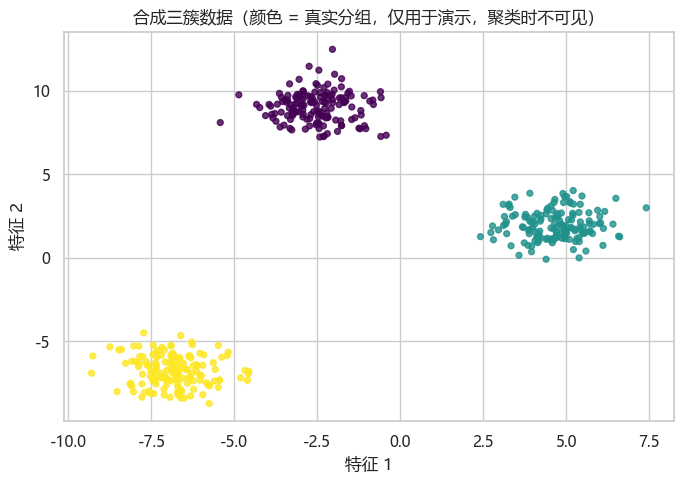

样本数: 450 | 特征数: 2


In [3]:
# 先造一份"三簇"数据：二维特征，每簇 150 个点
X_blob, y_blob = make_blobs(n_samples=450, centers=3, cluster_std=0.9,
                            random_state=RANDOM_STATE)
#make_blobs 是 sklearn.datasets 里的一个工具函数，用来生成“球形簇”的二维/多维数据，非常适合聚类演示。
#参数                 含义
# n_samples=450      总共生成 450 个样本
# centers=3          数据分为 3 个簇（类）
# cluster_std=0.9    每个簇内部点的分散程度（标准差），越小越集中
# random_state=RANDOM_STATE   随机种子，保证每次运行结果一致
fig, ax = plt.subplots(figsize=(7, 5))  #创建一个 7×5 英寸 的画布  ax 是坐标轴对象，后面所有绘图都作用在它上面
ax.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap='viridis', s=18, alpha=0.8)
#参数             含义
# X_blob[:, 0]      第 1 个特征（横轴）
# X_blob[:, 1]      第 2 个特征（纵轴）
# c=y_blob          点的颜色由真实簇标签决定
# cmap='viridis'    配色方案（不同簇不同颜色）
# s=18              点的大小
# alpha=0.8           透明度（防止点重叠看不清）
ax.set_xlabel('特征 1')
ax.set_ylabel('特征 2')
ax.set_title('合成三簇数据（颜色 = 真实分组，仅用于演示，聚类时不可见）')
plt.tight_layout()
plt.show()
print('样本数:', X_blob.shape[0], '| 特征数:', X_blob.shape[1])

In [4]:
# KMeans 三步走（初始化→分配→更新，sklearn 内部自动完成）
km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
# 初始化    随机选 10 组初始质心（n_init=10）
# 分配    每个点分配到最近的簇中心
# 更新   重新计算每个簇的中心
# 迭代    重复“分配→更新”，直到质心不再明显变化
labels_km = km.fit_predict(X_blob)   #一步完成，返回每个样本的预测簇编号（0 / 1 / 2）

d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


学到的 3 个簇中心：
 [[-2.55  9.03]
 [-6.86 -6.77]
 [ 4.66  1.94]]
inertia（簇内平方和，越小越好）: 697.6
迭代次数: 2


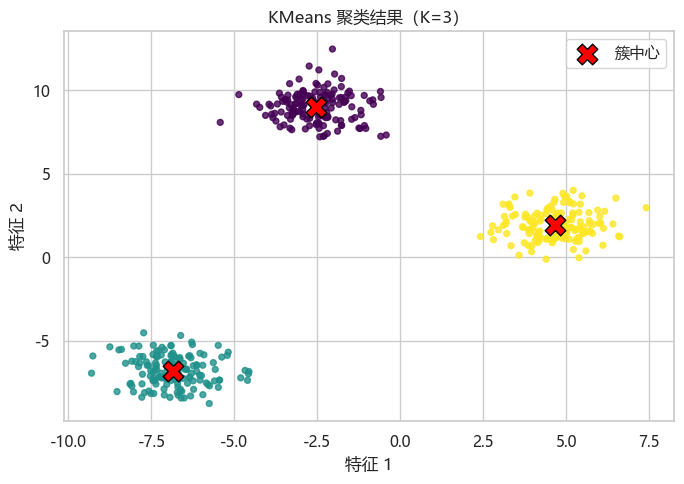

与真实分组的一致性 ARI = 1.000


In [5]:
print('学到的 3 个簇中心：\n', km.cluster_centers_.round(2))
# cluster_centers_ —— 学到的簇中心
# 形状 (3, 2)，即 3 个中心，每个中心有 2 个特征坐标
# 这是 K-Means 真正“学到”的东西
# 后续新数据可以直接用这些中心做预测
print('inertia（簇内平方和，越小越好）:', round(km.inertia_, 1)) #所有样本到其所属簇中心的距离平方和•✅ 越小越好，说明簇内越紧凑
print('迭代次数:', km.n_iter_)
# n_iter_ —— 实际迭代次数
# •模型跑了多少轮“分配→更新”才收敛
# •通常远小于 max_iter=300

# 可视化：点的颜色 = 预测簇编号，大红叉 = 簇中心
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_blob[:, 0], X_blob[:, 1], c=labels_km, cmap='viridis', s=18, alpha=0.8)
ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
           marker='X', s=220, c='red', edgecolor='black', label='簇中心')
ax.set_xlabel('特征 1')
ax.set_ylabel('特征 2')
ax.set_title('KMeans 聚类结果（K=3）')
ax.legend()
plt.tight_layout()
plt.show()

# 和"真实分组"比一比：adjusted_rand_score = 1 表示完全一致（簇编号允许任意换）
print(f'与真实分组的一致性 ARI = {adjusted_rand_score(y_blob, labels_km):.3f}')

d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You c

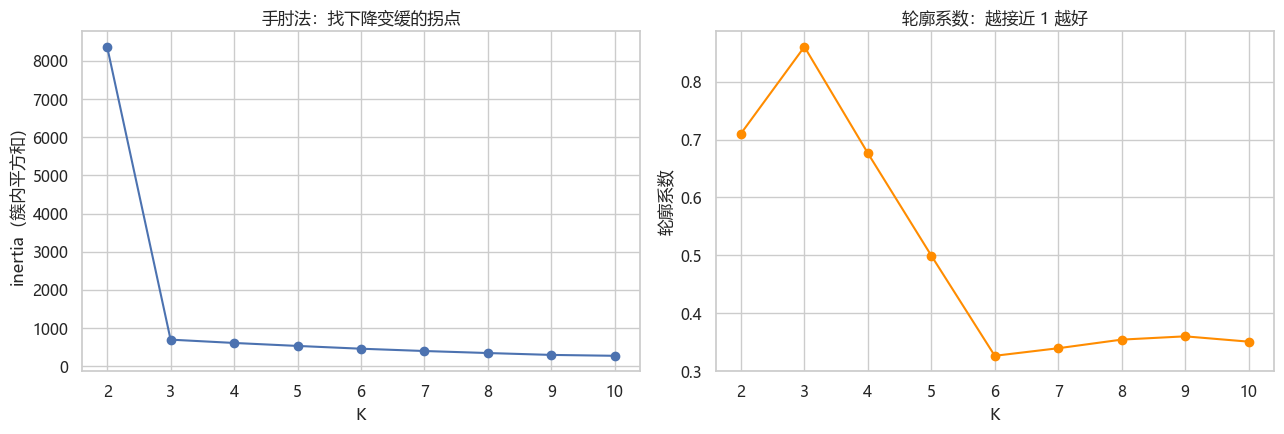

In [6]:
# 扫描 K = 2..10：手肘图（inertia）+ 轮廓系数
Ks = list(range(2, 11))
inertias, silhouettes = [], []
for k in Ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_blob)
    inertias.append(km_k.inertia_)
    silhouettes.append(silhouette_score(X_blob, km_k.labels_))
# 对每个 K（从 2 到 10）：
# 1.训练一个 K-Means 模型
# 2.记录 inertia_（簇内平方和，SSE）
# 3.用 silhouette_score() 计算整体轮廓系数


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(Ks, inertias, 'o-')
axes[0].set_xlabel('K')
axes[0].set_ylabel('inertia（簇内平方和）')
axes[0].set_title('手肘法：找下降变缓的拐点')
axes[1].plot(Ks, silhouettes, 'o-', color='darkorange')
axes[1].set_xlabel('K')
axes[1].set_ylabel('轮廓系数')
axes[1].set_title('轮廓系数：越接近 1 越好')
plt.tight_layout()
plt.show()

In [7]:
# 定量看 inertia 的下降速度
drops = [inertias[i - 1] - inertias[i] for i in range(1, len(inertias))]#计算相邻 K 之间 SSE 的减少量
drop_df = pd.DataFrame({'K': Ks[1:],
                        'inertia': np.round(inertias[1:], 1),
                        '相比上一K的下降': np.round(drops, 1),
                        '轮廓系数': np.round(silhouettes[1:], 3)})
display(drop_df.set_index('K'))
print('解读：inertia 必然随 K 下降，要看"下降速度"在哪放缓；本例中轮廓系数在 K=3 达到峰值（0.86）。')

,inertia,相比上一K的下降,轮廓系数
K,,,
3,697.6000,"7,672.0000",0.8600
4,610.9000,86.7000,0.6770
5,532.9000,78.0000,0.5000
6,460.1000,72.8000,0.3260
7,399.7000,60.3000,0.3400
8,346.7000,53.0000,0.3540
9,297.6000,49.2000,0.3600
10,274.4000,23.2000,0.3510


解读：inertia 必然随 K 下降，要看"下降速度"在哪放缓；本例中轮廓系数在 K=3 达到峰值（0.86）。


d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


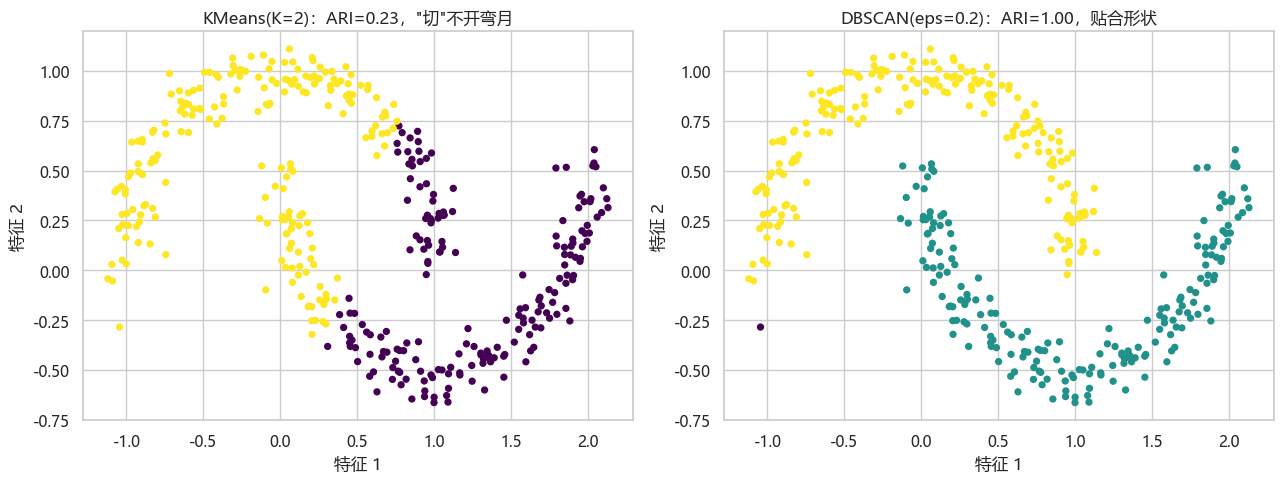

结论：KMeans 假设簇是球形/凸的，遇到非凸形状就失效；
      DBSCAN 基于密度，能贴合任意形状（第六节详细讲）。


In [8]:
# KMeans 的经典失败现场：两个交错的月牙
X_moon, y_moon = make_moons(n_samples=400, noise=0.08, random_state=RANDOM_STATE)
km_moon = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_moon)
db_moon = DBSCAN(eps=0.2, min_samples=5).fit_predict(X_moon)
# 用 DBSCAN 算法对 X_moon 数据进行密度聚类，返回每个点的簇标签。
# K-Means  "距离谁近就归谁"——基于质心的划分
# DBSCAN    "密集的地方就是一簇"——基于密度的连接


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_moon[:, 0], X_moon[:, 1], c=km_moon, cmap='viridis', s=18)
axes[0].set_title(f'KMeans(K=2)：ARI={adjusted_rand_score(y_moon, km_moon):.2f}，"切"不开弯月')
axes[1].scatter(X_moon[:, 0], X_moon[:, 1], c=db_moon, cmap='viridis', s=18)
axes[1].set_title(f'DBSCAN(eps=0.2)：ARI={adjusted_rand_score(y_moon, db_moon):.2f}，贴合形状')
for ax in axes:
    ax.set_xlabel('特征 1')
    ax.set_ylabel('特征 2')
plt.tight_layout()
plt.show()
print('结论：KMeans 假设簇是球形/凸的，遇到非凸形状就失效；')
print('      DBSCAN 基于密度，能贴合任意形状（第六节详细讲）。')

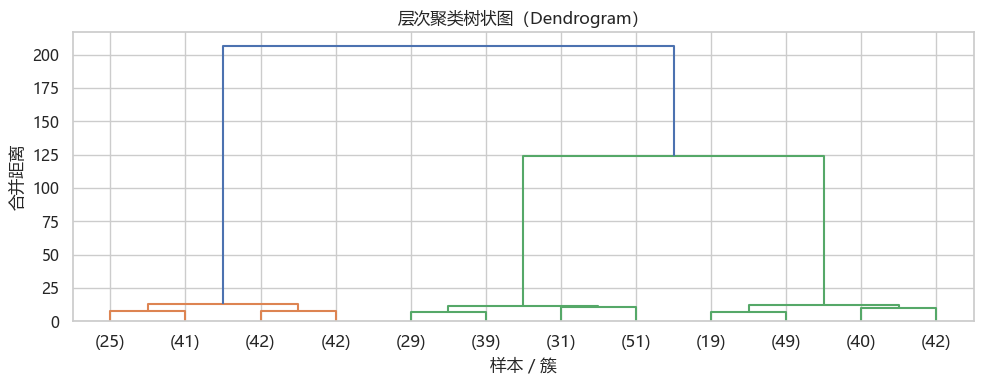

In [9]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import matplotlib.pyplot as plt

# 1. 计算连接矩阵
Z = linkage(X_blob, method='ward')

# 2. 切树得到标签（类似指定 K）
labels_hc = fcluster(Z, t=3, criterion='maxclust')
# t=3 表示要 3 个簇

# 3. 画树状图（可选）
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=12)  # 只显示最后 12 次合并
plt.xlabel('样本 / 簇')
plt.ylabel('合并距离')
plt.title('层次聚类树状图（Dendrogram）')
plt.tight_layout()
plt.show()

In [10]:
# ===== 实战一：wine 数据集聚类全流程 =====
wine = load_wine()
Xw, yw = wine.data, wine.target
print('wine:', Xw.shape, '| 真实品种数:', len(np.unique(yw)))

# 1) 缩放前后 KMeans(3) 的天壤之别——量纲又绑架了一次
pipe_w = Pipeline([('scaler', StandardScaler()),
                   ('km', KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE))]) 
#使用 Pipeline 进行「标准化 + K-Means」先标准化 → 再聚类，流程严谨、防止数据泄露
pipe_w.fit(Xw)
labels_w = pipe_w.named_steps['km'].labels_  #标准化后 K-Means 的聚类结果（簇标签）
Xw_s = pipe_w.named_steps['scaler'].transform(Xw)  #标准化后的特征矩阵（用于后续计算轮廓系数）
km_raw = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xw) #对照组：不做标准化的 K-Means
ari_raw = adjusted_rand_score(yw, km_raw.labels_)  #ARI（Adjusted Rand Index）衡量预测分组与真实品种标签的一致性 范围：[-1, 1]，越接近 1 越好
ari_sc = adjusted_rand_score(yw, labels_w)
sil_raw = silhouette_score(Xw, km_raw.labels_)  #轮廓系数（Silhouette Score）衡量簇内紧凑度 + 簇间分离度 范围：[-1, 1]，越接近 1 越好
sil_sc = silhouette_score(Xw_s, labels_w)
print(f'不缩放：ARI = {ari_raw:.3f} | 轮廓系数 = {sil_raw:.3f}')
print(f'缩放后：ARI = {ari_sc:.3f} | 轮廓系数 = {sil_sc:.3f}')
print(f'解读：ARI 从 {ari_raw:.3f} 跳到 {ari_sc:.3f}——缩放后的聚类真正贴合了品种结构；')
print(f'      但轮廓系数反而从 {sil_raw:.3f} 降到 {sil_sc:.3f}：轮廓系数偏爱"球形紧簇"，')
print('      而真实品种结构并非球形。这正是第七节的提醒——指标是参考，不是真理。')

wine: (178, 13) | 真实品种数: 3


d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


不缩放：ARI = 0.371 | 轮廓系数 = 0.571
缩放后：ARI = 0.897 | 轮廓系数 = 0.285
解读：ARI 从 0.371 跳到 0.897——缩放后的聚类真正贴合了品种结构；
      但轮廓系数反而从 0.571 降到 0.285：轮廓系数偏爱"球形紧簇"，
      而真实品种结构并非球形。这正是第七节的提醒——指标是参考，不是真理。


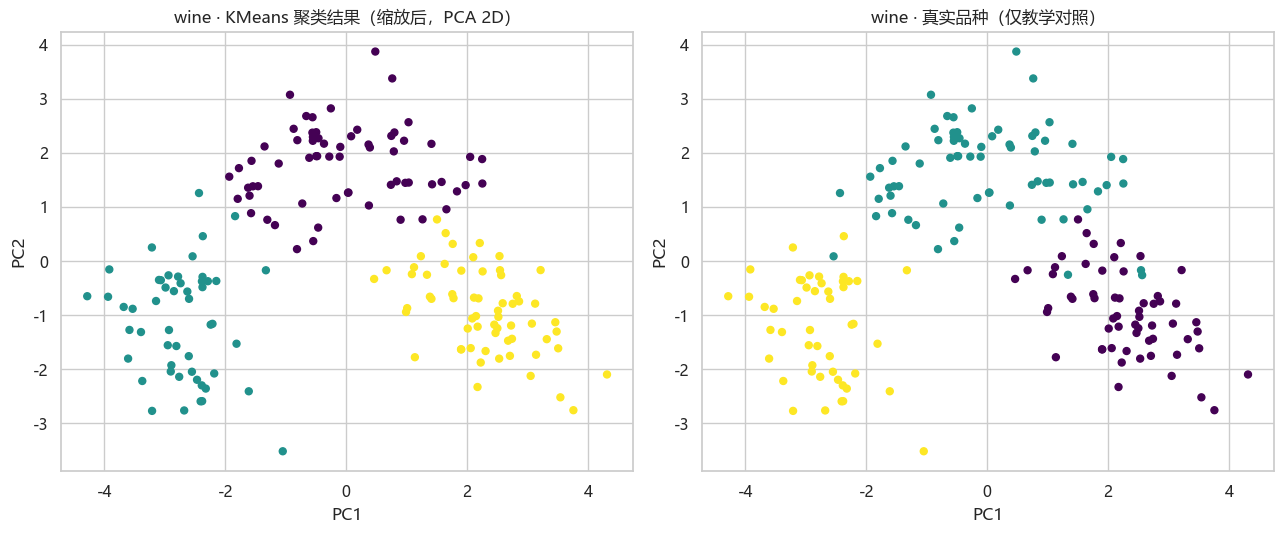

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
簇,,,,,,,,,,,,,
0,12.2500,1.9000,2.2300,20.0600,92.7400,2.2500,2.0500,0.3600,1.6200,2.9700,1.0600,2.8000,510.1700
1,13.1300,3.3100,2.4200,21.2400,98.6700,1.6800,0.8200,0.4500,1.1500,7.2300,0.6900,1.7000,619.0600
2,13.6800,2.0000,2.4700,17.4600,107.9700,2.8500,3.0000,0.2900,1.9200,5.4500,1.0700,3.1600,"1,100.2300"


解读任务：找出每个簇的"个性特征"——哪个簇酒精最高？哪个簇脯氨酸最高？哪个最"清淡"？


In [11]:
# 2) PCA 降到 2 维可视化（缩放后的数据上做 PCA）
Xw_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xw_s)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(Xw_pca[:, 0], Xw_pca[:, 1], c=labels_w, cmap='viridis', s=25)
axes[0].set_title('wine · KMeans 聚类结果（缩放后，PCA 2D）')
axes[1].scatter(Xw_pca[:, 0], Xw_pca[:, 1], c=yw, cmap='viridis', s=25)
axes[1].set_title('wine · 真实品种（仅教学对照）')
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

# 3) 簇画像：每个簇在 13 个特征上的均值（原始量纲，便于解读）
profile = pd.DataFrame(Xw, columns=wine.feature_names)
profile['簇'] = labels_w
display(profile.groupby('簇').mean().round(2))
print('解读任务：找出每个簇的"个性特征"——哪个簇酒精最高？哪个簇脯氨酸最高？哪个最"清淡"？')

In [12]:
# ===== 实战二：广电用户分群 =====
n_per = 200
seg_heavy = pd.DataFrame({          # 重度活跃用户
    '日均观看时长(h)': rng.normal(5.0, 0.6, n_per),
    '月点播次数': rng.poisson(75, n_per),
    '月活跃天数': rng.randint(20, 31, n_per),
    '月客服投诉': rng.poisson(0.3, n_per)})
seg_mid = pd.DataFrame({            # 普通活跃用户
    '日均观看时长(h)': rng.normal(2.0, 0.5, n_per),
    '月点播次数': rng.poisson(15, n_per),
    '月活跃天数': rng.randint(8, 20, n_per),
    '月客服投诉': rng.poisson(0.8, n_per)})
seg_sleep = pd.DataFrame({          # 沉睡/易流失用户
    '日均观看时长(h)': rng.normal(0.5, 0.3, n_per),
    '月点播次数': rng.poisson(3, n_per),
    '月活跃天数': rng.randint(1, 8, n_per),
    '月客服投诉': rng.poisson(1.5, n_per)})
users = pd.concat([seg_heavy, seg_mid, seg_sleep], ignore_index=True).clip(lower=0).round(1)
display(users.head())
print('用户数:', len(users), '| 特征:', list(users.columns))

,日均观看时长(h),月点播次数,月活跃天数,月客服投诉
0,5.3000,87,26,0
1,4.9000,80,27,0
2,5.4000,71,22,0
3,5.9000,75,25,0
4,4.9000,83,20,0


用户数: 600 | 特征: ['日均观看时长(h)', '月点播次数', '月活跃天数', '月客服投诉']


d:\pyan\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


轮廓系数 = 0.525


,日均观看时长(h),月点播次数,月活跃天数,月客服投诉
分群,,,,
0,4.9800,73.1800,24.8400,0.3000
1,1.4200,10.0700,9.6000,0.4800
2,1.0200,6.6200,7.2300,2.5000


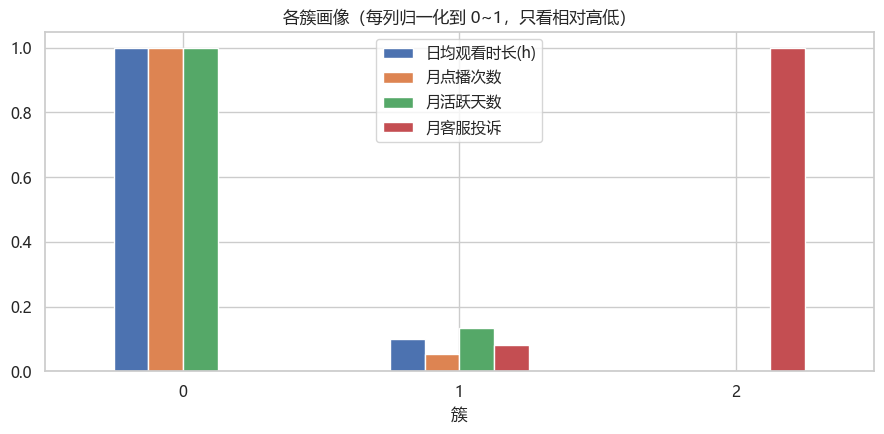

自动命名结果（按日均观看时长排序）：
  簇0: 高价值忠诚用户 → 维护关系 + 会员增值
  簇1: 普通活跃用户 → 内容推荐提频
  簇2: 沉睡/易流失用户 → 优惠召回 + 服务修复；投诉偏高，先修服务再营销

课堂提问：如果运营只看"月点播次数"一个指标做分群，会丢失什么信息？


In [13]:
# 缩放 → KMeans(K=3) → 评估
Xu = StandardScaler().fit_transform(users)
km_u = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xu)
users['分群'] = km_u.labels_
print(f'轮廓系数 = {silhouette_score(Xu, km_u.labels_):.3f}')

# 各簇画像（还原到原始量纲）
profile_u = users.groupby('分群').mean().round(2)
display(profile_u)

# 归一化后的画像条形图：直观看每个簇的"个性"
prof_norm = (profile_u - profile_u.min()) / (profile_u.max() - profile_u.min())
prof_norm.plot.bar(figsize=(9, 4.5))
plt.title('各簇画像（每列归一化到 0~1，只看相对高低）')
plt.xlabel('簇')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 业务命名：按"日均观看时长"给簇排序命名（排序法不依赖具体阈值，换数据也成立）
order = profile_u['日均观看时长(h)'].sort_values(ascending=False).index.tolist()
name_by_rank = ['高价值忠诚用户 → 维护关系 + 会员增值',
                '普通活跃用户 → 内容推荐提频',
                '沉睡/易流失用户 → 优惠召回 + 服务修复']
worst_service = profile_u['月客服投诉'].idxmax()   # 投诉最高的簇，优先修服务
seg_names = {}
for rank, g in enumerate(order):
    name = name_by_rank[rank] if rank < len(name_by_rank) else f'簇{g}（自定义）'
    if g == worst_service:
        name += '；投诉偏高，先修服务再营销'
    seg_names[g] = name
print('自动命名结果（按日均观看时长排序）：')
for g, name in seg_names.items():
    print(f'  簇{g}: {name}')
print('\n课堂提问：如果运营只看"月点播次数"一个指标做分群，会丢失什么信息？')

In [ ]:
# ===== 环境与全局设置 =====
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

from sklearn.datasets import make_moons, load_wine
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')   # 先设 seaborn 主题——它会重置 font.sans-serif！

# 中文字体：必须在 seaborn set_theme 之后再配置，否则会被覆盖回 Arial（中文全变方框）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'PingFang SC',
                                   'Hiragino Sans GB', 'Noto Sans CJK SC',
                                   'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
for _f in ['C:/Windows/Fonts/msyh.ttc', 'C:/Windows/Fonts/simhei.ttf']:
    if os.path.exists(_f):
        try:
            fm.fontManager.addfont(_f)
        except Exception:
            pass

pd.set_option('display.width', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

%matplotlib inline

RANDOM_STATE = 42
print('环境就绪 | numpy', np.__version__, '| pandas', pd.__version__)

# ===== 课程数据集：wine（前三讲一直在用，保持连续性） =====
wine = load_wine()
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(
    wine.data, wine.target, test_size=0.25, random_state=RANDOM_STATE, stratify=wine.target)
print(f'wine：训练 {Xw_tr.shape} | 测试 {Xw_te.shape} | 特征 {len(wine.feature_names)} 个')

环境就绪 | numpy 1.26.4 | pandas 2.2.2
wine：训练 (133, 13) | 测试 (45, 13) | 特征 13 个


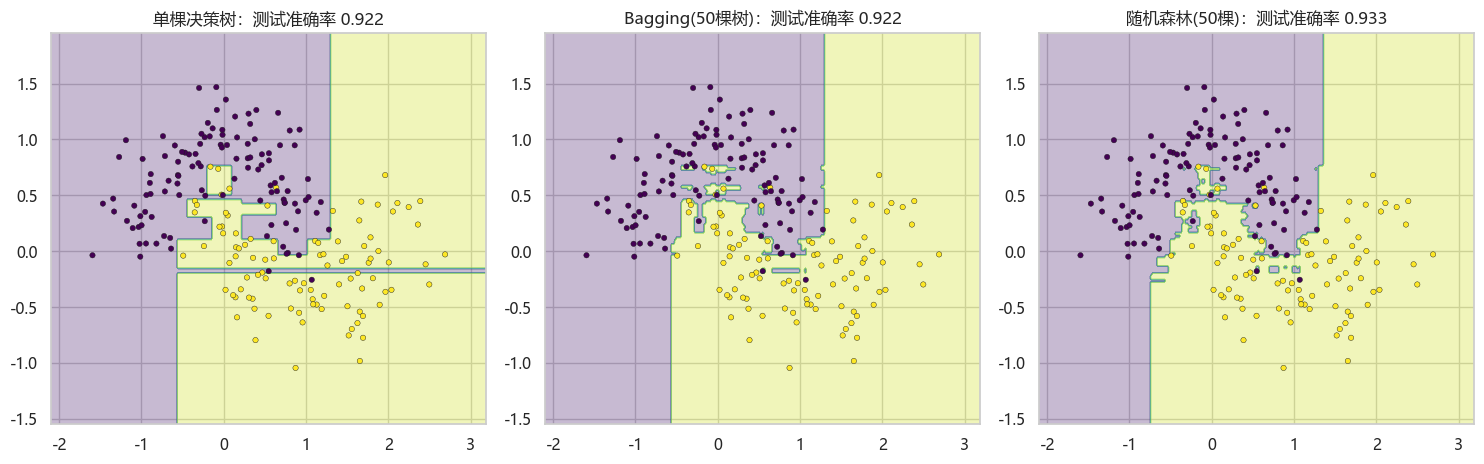

看边界形状：单棵树的边界"破碎"（记住噪声）；集成之后边界平滑——方差被平均掉了。


In [15]:
# 先看效果：单棵深树 vs Bagging vs 随机森林，在带噪声的 moons 数据上
X_moon, y_moon = make_moons(n_samples=300, noise=0.25, random_state=RANDOM_STATE) #生成 300 个点的月牙形数据，noise=0.25 让边界模糊
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_moon, y_moon, test_size=0.3, random_state=RANDOM_STATE)  #70% 训练（210 个），30% 测试（90 个）

def plot_boundary(ax, model, X, y, title):  #决策边界可视化函数
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5  # 确定画布范围x_min, x_max, y_min, y_max比数据稍大一圈（±0.5）
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),  #生成网格点np.meshgrid(...)以 0.02 为步长，生成整个平面的点阵
                         np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)#预测每个网格点model.predict(np.c_[xx.ravel(), yy.ravel()])把每个网格点喂给模型，得到类别预测
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')#画背景色ax.contourf(...)用颜色填充不同类别的区域（决策边界的可视化）
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=15, edgecolor='k', linewidth=0.3)#叠上真实数据点黑边小点 = 训练数据
    ax.set_title(title)

tree1 = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xm_tr, ym_tr)#单棵决策树默认参数（无最大深度限制）会一直分裂到纯节点 → 记住噪声
bag = BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE),
                        n_estimators=50, random_state=RANDOM_STATE).fit(Xm_tr, ym_tr) #Bagging50 棵相同的树，Bootstrap 采样 并行训练，投票平均
rf = RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE).fit(Xm_tr, ym_tr)#随机森林50 棵树 + 随机特征子集 Bagging + 特征随机性 → 多样性更强
#Bagging：每棵树看到不同的数据子集（Bootstrap），但特征全用
# 随机森林：每棵树看到不同的数据子集 + 不同的特征子集 → 多样性更高
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
plot_boundary(axes[0], tree1, Xm_tr, ym_tr, f'单棵决策树：测试准确率 {tree1.score(Xm_te, ym_te):.3f}')
plot_boundary(axes[1], bag, Xm_tr, ym_tr, f'Bagging(50棵树)：测试准确率 {bag.score(Xm_te, ym_te):.3f}')
plot_boundary(axes[2], rf, Xm_tr, ym_tr, f'随机森林(50棵)：测试准确率 {rf.score(Xm_te, ym_te):.3f}')
plt.tight_layout()
plt.show()
print('看边界形状：单棵树的边界"破碎"（记住噪声）；集成之后边界平滑——方差被平均掉了。')

"左边这张图是一棵没加任何限制的决策树。你看它的边界——锯齿状、破碎、像锯齿一样。 为什么？因为决策树没有深度限制，它会一直分裂到每个叶子节点都'纯'。结果就是：训练集里的噪声点也被它记住了。 这就是高方差——模型对训练数据太敏感，换个训练集边界就完全变了。" 单棵树 = 过拟合 = 边界破碎 = 高方差
"中间这张图是 50 棵树做 Bagging。每棵树用 Bootstrap 采样得到不同的训练子集，然后投票。 你看到边界比左边平滑了——为什么？ 因为每棵树记住的噪声点不一样。投票的时候，某棵树记住的噪声被其他树'否决'了。数学上，平均 50 个不相关的模型的方差，变成原来的 1/50。" Bagging = 多棵树投票 = 噪声互相抵消 = 方差 ↓
"右边是随机森林——在 Bagging 基础上，每棵树还随机选特征子集。 边界比 Bagging 更平滑、更合理。为什么？因为多样性更高——不仅数据不同，看的特征也不同，树之间的相关性更低，平均后方差降得更多。" 随机森林 = Bagging + 随机特征 = 多样性↑ = 方差↓↓

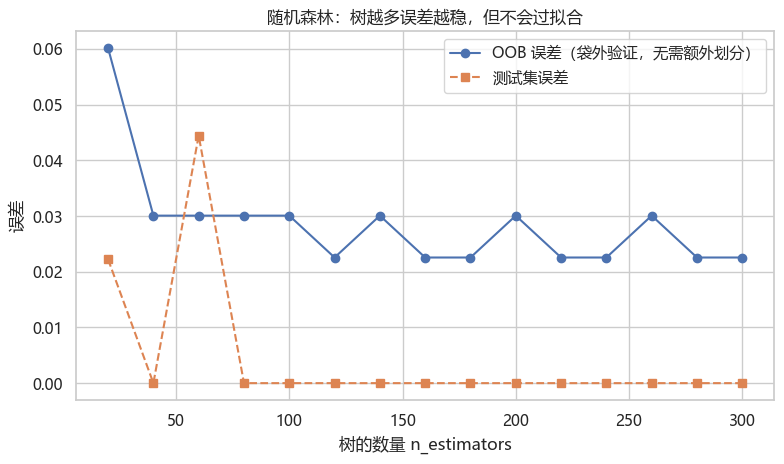

300 棵时：OOB 准确率 = 0.9774 | 测试准确率 = 1.0000
注意：OOB 是在训练过程中"顺带"算出来的——小数据集上可以省下整个验证集。


In [16]:
# OOB 误差与袋外得分：树加到 300 棵，误差只会收敛、不会过拟合
rf_warm = RandomForestClassifier(n_estimators=20, oob_score=True, warm_start=True,
                                 random_state=RANDOM_STATE)
#n_estimators=20    初始 20 棵树
# oob_score=True      启用袋外评分——每棵树用"没被采样到的样本"做验证
# warm_start=True     关键：后续 set_params(n_estimators=n) 时，不重新训练已有的树，只追加新树
# warm_start=True 的意义：不用每次从零训练 300 棵树，而是从 20→40→60…逐步追加，大幅节省计算时间。
n_trees, oob_err, test_err = [], [], []
for n in range(20, 301, 20):  #循环从 20 棵树到 300 棵树，步长 20：
    rf_warm.set_params(n_estimators=n)   #更新树数 set_params(n_estimators=n) 告诉模型"现在要 n 棵树"
    rf_warm.fit(Xw_tr, yw_tr)    #增量训练 fit(Xw_tr, yw_tr) 已有树保留，只训练新增的树
    n_trees.append(n)
    oob_err.append(1 - rf_warm.oob_score_)  #记录 OOB 误差 1 - rf_warm.oob_score 袋外准确率取反 = 误差率
    test_err.append(1 - rf_warm.score(Xw_te, yw_te)) #记录测试误差 1 - rf_warm.score(Xw_te, yw_te) 在独立测试集上的误差

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(n_trees, oob_err, 'o-', label='OOB 误差（袋外验证，无需额外划分）')
ax.plot(n_trees, test_err, 's--', label='测试集误差')
ax.set_xlabel('树的数量 n_estimators')
ax.set_ylabel('误差')
ax.set_title('随机森林：树越多误差越稳，但不会过拟合')
ax.legend()
plt.tight_layout()
plt.show()
print(f'300 棵时：OOB 准确率 = {rf_warm.oob_score_:.4f} | 测试准确率 = {rf_warm.score(Xw_te, yw_te):.4f}')
print('注意：OOB 是在训练过程中"顺带"算出来的——小数据集上可以省下整个验证集。')

In [17]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
ada50 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=RANDOM_STATE
)
ada50.fit(Xw_tr, yw_tr)

print("\n" + "=" * 60)
print("【AdaBoost】50 棵决策树桩（learning_rate=1.0）")
print("=" * 60)
print(f"训练准确率: {ada50.score(Xw_tr, yw_tr):.4f}")
print(f"测试准确率: {ada50.score(Xw_te, yw_te):.4f}")


【AdaBoost】50 棵决策树桩（learning_rate=1.0）
训练准确率: 0.9323
测试准确率: 0.8444


d:\pyan\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


In [18]:
ada200 = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=200,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)
ada200.fit(Xw_tr, yw_tr)

print("\n" + "=" * 60)
print("【AdaBoost】200 棵决策树桩（learning_rate=0.5）")
print("=" * 60)
print(f"训练准确率: {ada200.score(Xw_tr, yw_tr):.4f}")
print(f"测试准确率: {ada200.score(Xw_te, yw_te):.4f}")

d:\pyan\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(



【AdaBoost】200 棵决策树桩（learning_rate=0.5）
训练准确率: 1.0000
测试准确率: 0.9556


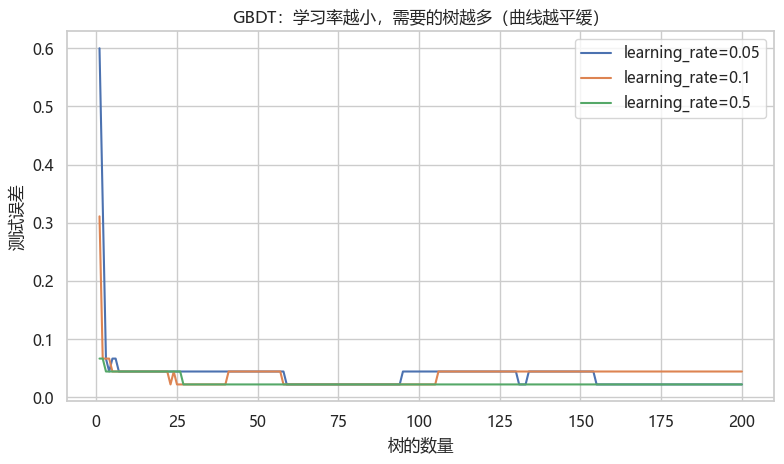

d:\pyan\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


,训练准确率,测试准确率
模型,,
单棵决策树,1.0000,0.9556
AdaBoost(决策桩),0.9323,0.8444
GBDT,1.0000,0.9778
随机森林(200棵),1.0000,1.0000


解读：单棵树训练准确率 1.0——把训练集（含噪声）背得滚瓜烂熟；
      集成之后训练分依然是 1.0，但测试分从 0.956 提升到 1.000——
      集成没有牺牲训练表现，却换来了更好的泛化：方差被平均掉了。


In [19]:
# Boosting 的两个旋钮：学习率与树数必须一起调（GBDT 在 wine 上）
fig, ax = plt.subplots(figsize=(8, 4.8))
for lr in [0.05, 0.1, 0.5]:
    gb = GradientBoostingClassifier(learning_rate=lr, n_estimators=200,
                                    random_state=RANDOM_STATE)
    gb.fit(Xw_tr, yw_tr)
    staged = [1 - (pred == yw_te).mean() for pred in gb.staged_predict(Xw_te)]  # 每加一棵树的测试误差
    ax.plot(range(1, 201), staged, label=f'learning_rate={lr}')
ax.set_xlabel('树的数量')
ax.set_ylabel('测试误差')
ax.set_title('GBDT：学习率越小，需要的树越多（曲线越平缓）')
ax.legend()
plt.tight_layout()
plt.show()

# 横向对比：单模型 vs 三种集成（同一训练/测试划分）
rows = []
models = [('单棵决策树', DecisionTreeClassifier(random_state=RANDOM_STATE)),
          ('AdaBoost(决策桩)', AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)),
          ('GBDT', GradientBoostingClassifier(random_state=RANDOM_STATE)),
          ('随机森林(200棵)', RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]
for name, m in models:
    m.fit(Xw_tr, yw_tr)
    rows.append({'模型': name,
                 '训练准确率': m.score(Xw_tr, yw_tr),
                 '测试准确率': m.score(Xw_te, yw_te)})
display(pd.DataFrame(rows).set_index('模型').round(4))
tree_te = rows[0]['测试准确率']
ens_te = max(r['测试准确率'] for r in rows[1:])
print(f'解读：单棵树训练准确率 1.0——把训练集（含噪声）背得滚瓜烂熟；')
print(f'      集成之后训练分依然是 1.0，但测试分从 {tree_te:.3f} 提升到 {ens_te:.3f}——')
print('      集成没有牺牲训练表现，却换来了更好的泛化：方差被平均掉了。')

In [20]:
# 混搭三种不同家族的模型：Voting vs Stacking（wine 数据集）
lr_pipe = Pipeline([('scaler', StandardScaler()),
                    ('lr', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
knn_pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])
rf_base = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
estimators = [('逻辑回归', lr_pipe), ('KNN', knn_pipe), ('随机森林', rf_base)]

voters = [('硬投票', VotingClassifier(estimators=estimators, voting='hard')),
          ('软投票', VotingClassifier(estimators=estimators, voting='soft')),
          ('Stacking', StackingClassifier(estimators=estimators,
                                          final_estimator=LogisticRegression(max_iter=2000),
                                          cv=5))]

rows = []
for name, m in voters:
    cv_scores = cross_val_score(m, Xw_tr, yw_tr, cv=5)
    m.fit(Xw_tr, yw_tr)
    rows.append({'组合方式': name,
                 'CV 准确率(训练集5折)': cv_scores.mean(),
                 '测试准确率': m.score(Xw_te, yw_te)})
display(pd.DataFrame(rows).set_index('组合方式').round(4))
print('注意：Stacking 内部用 5 折交叉验证生成元特征——每折重新训练基模型，不存在数据泄漏。')
print('      三个基模型单独的成绩单打印在下面，供对照。')
for name, m in estimators:
    cv_s = cross_val_score(m, Xw_tr, yw_tr, cv=5).mean()
    print(f'  基模型 {name:6s} CV 准确率 = {cv_s:.4f}')

,CV 准确率(训练集5折),测试准确率
组合方式,,
硬投票,0.9772,1.0000
软投票,0.9846,0.9778
Stacking,0.9846,0.9778


注意：Stacking 内部用 5 折交叉验证生成元特征——每折重新训练基模型，不存在数据泄漏。
      三个基模型单独的成绩单打印在下面，供对照。
  基模型 逻辑回归   CV 准确率 = 0.9849
  基模型 KNN    CV 准确率 = 0.9550
  基模型 随机森林   CV 准确率 = 0.9698


In [21]:
import numpy as np
import pandas as pd

np.set_printoptions(precision=4, suppress=True)

# 1. 示例数据
data = {
    'item_id': [1, 2, 3, 4, 5],
    'item_name': ['apple', 'orange', 'banana', 'strawberry', 'pineapple'],
    'item_description': [
        'a crisp and juicy red fruit commonly eaten raw',
        'a citrus fruit with bright orange skin and sweet-tart flavor',
        'a long curved tropical fruit with soft sweet yellow flesh',
        'a small red heart-shaped berry with a sweet aromatic flavor',
        'a tropical fruit with rough spiky skin and sweet yellow flesh'
    ]
}
df = pd.DataFrame(data)

# 2. TF-IDF 向量化
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['item_description'])

print("TF-IDF 矩阵形状:", tfidf_matrix.shape)
print("特征词表:", list(tfidf.get_feature_names_out()))

TF-IDF 矩阵形状: (5, 27)
特征词表: ['aromatic', 'berry', 'bright', 'citrus', 'commonly', 'crisp', 'curved', 'eaten', 'flavor', 'flesh', 'fruit', 'heart', 'juicy', 'long', 'orange', 'raw', 'red', 'rough', 'shaped', 'skin', 'small', 'soft', 'spiky', 'sweet', 'tart', 'tropical', 'yellow']


In [22]:
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    index=df['item_name'],          # 行：商品名
    columns=tfidf.get_feature_names_out()  # 列：特征词
)

print(tfidf_df,tfidf_df.shape)

            aromatic  berry  bright  citrus  commonly  crisp  curved  eaten  flavor  flesh  ...  rough  shaped   skin  \
item_name                                                                                   ...                         
apple         0.0000 0.0000  0.0000  0.0000    0.4093 0.4093  0.0000 0.4093  0.0000 0.0000  ... 0.0000  0.0000 0.0000   
orange        0.0000 0.0000  0.4104  0.4104    0.0000 0.0000  0.0000 0.0000  0.3311 0.0000  ... 0.0000  0.0000 0.3311   
banana        0.0000 0.0000  0.0000  0.0000    0.0000 0.0000  0.4230 0.0000  0.0000 0.3413  ... 0.0000  0.0000 0.0000   
strawberry    0.3887 0.3887  0.0000  0.0000    0.0000 0.0000  0.0000 0.0000  0.3136 0.0000  ... 0.0000  0.3887 0.0000   
pineapple     0.0000 0.0000  0.0000  0.0000    0.0000 0.0000  0.0000 0.0000  0.0000 0.3525  ... 0.4369  0.0000 0.3525   

            small   soft  spiky  sweet   tart  tropical  yellow  
item_name                                                        
apple      0.0000 0.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
import pandas as pd

cos_sim = cosine_similarity(tfidf_matrix)#余弦相似度
lin_ker = linear_kernel(tfidf_matrix)#线性核函数

item_names = df['item_name'].tolist()

cos_df = pd.DataFrame(cos_sim, index=item_names, columns=item_names)
lin_df = pd.DataFrame(lin_ker, index=item_names, columns=item_names)

In [24]:
# 关键：norm=None 关闭默认归一化
tfidf_unnorm = TfidfVectorizer(stop_words='english', norm=None)
mat_unnorm = tfidf_unnorm.fit_transform(df['item_description'])

cos_sim = cosine_similarity(mat_unnorm)
lin_ker = linear_kernel(mat_unnorm)

In [25]:
from sklearn.metrics.pairwise import linear_kernel, cosine_similarity  # TF-IDF 已归一化，二者等价

cos_sim = cosine_similarity(tfidf_matrix)
print("余弦相似度矩阵:")
print(pd.DataFrame(cos_sim.round(4), index=df['item_name'], columns=df['item_name']))

# 经典推荐循环：对每个商品排序 Top-N（去掉自身）
print("\n经典写法：相似度排序生成推荐")
for i in range(len(df)):
    sims = sorted(list(enumerate(cos_sim[i])), key=lambda x: x[1], reverse=True)[1:]
    recs = [(df.iloc[j]['item_name'], f"{s:.4f}") for j, s in sims]
    print(f"  因为您喜欢 '{df.iloc[i]['item_name']}'，推荐：{recs}")

余弦相似度矩阵:
item_name   apple  orange  banana  strawberry  pineapple
item_name                                               
apple      1.0000  0.0533  0.0550      0.1036     0.0568
orange     0.0533  1.0000  0.1102      0.1545     0.2306
banana     0.0550  0.1102  1.0000      0.0522     0.4783
strawberry 0.1036  0.1545  0.0522      1.0000     0.0539
pineapple  0.0568  0.2306  0.4783      0.0539     1.0000

经典写法：相似度排序生成推荐
  因为您喜欢 'apple'，推荐：[('strawberry', '0.1036'), ('pineapple', '0.0568'), ('banana', '0.0550'), ('orange', '0.0533')]
  因为您喜欢 'orange'，推荐：[('pineapple', '0.2306'), ('strawberry', '0.1545'), ('banana', '0.1102'), ('apple', '0.0533')]
  因为您喜欢 'banana'，推荐：[('pineapple', '0.4783'), ('orange', '0.1102'), ('apple', '0.0550'), ('strawberry', '0.0522')]
  因为您喜欢 'strawberry'，推荐：[('orange', '0.1545'), ('apple', '0.1036'), ('pineapple', '0.0539'), ('banana', '0.0522')]
  因为您喜欢 'pineapple'，推荐：[('banana', '0.4783'), ('orange', '0.2306'), ('apple', '0.0568'), ('strawberry', '0.0539')]


In [26]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(metric='cosine')
nn.fit(tfidf_matrix)
dist, idx = nn.kneighbors(tfidf_matrix, n_neighbors=3)   # 含自身，故每个商品得 2 个真近邻

In [27]:
print("NearestNeighbors(metric='cosine') 每个商品的 Top-3 近邻:")
for i, name in enumerate(df['item_name']):
    neigh = [(df.iloc[j]['item_name'], f"{1 - d:.4f}") for d, j in zip(dist[i], idx[i]) if j != i]
    print(f"  {name:<11} -> {neigh}")

NearestNeighbors(metric='cosine') 每个商品的 Top-3 近邻:
  apple       -> [('strawberry', '0.1036'), ('pineapple', '0.0568')]
  orange      -> [('pineapple', '0.2306'), ('strawberry', '0.1545')]
  banana      -> [('pineapple', '0.4783'), ('orange', '0.1102')]
  strawberry  -> [('orange', '0.1545'), ('apple', '0.1036')]
  pineapple   -> [('banana', '0.4783'), ('orange', '0.2306')]


In [28]:
rng = np.random.RandomState(42)
n_users, n_items = 8, 6
true_U = rng.rand(n_users, 2) * 2
true_V = rng.rand(n_items, 2) * 2
R_full = true_U @ true_V.T
R = np.where(R_full > 1.2, np.clip(R_full * 1.2, 1, 5).round(), 0)
# 保证每个用户至少评过 2 部、每部电影至少被 2 人评过（否则是冷启动）
for u in range(n_users):
    if (R[u] > 0).sum() < 2:
        for i in rng.choice(n_items, 2, replace=False):
            R[u, i] = np.clip(true_U[u] @ true_V[i] * 1.2, 1, 5).round()
for i in range(n_items):
    if (R[:, i] > 0).sum() < 2:
        for u in rng.choice(n_users, 2, replace=False):
            R[u, i] = np.clip(true_U[u] @ true_V[i] * 1.2, 1, 5).round()

items = ['电影A', '电影B', '电影C', '电影D', '电影E', '电影F']
R_df = pd.DataFrame(R, index=[f'用户{u+1}' for u in range(n_users)], columns=items)
observed = R > 0
print("评分矩阵（0 = 未评分）:")
print(R_df)
print(f"\n观测密度: {observed.mean():.1%}（真实场景通常 <5%，稀疏度才是常态）")

评分矩阵（0 = 未评分）:
       电影A    电影B    电影C    电影D    电影E    电影F
用户1 3.0000 2.0000 2.0000 2.0000 4.0000 3.0000
用户2 3.0000 2.0000 3.0000 2.0000 4.0000 2.0000
用户3 0.0000 1.0000 0.0000 1.0000 0.0000 0.0000
用户4 2.0000 0.0000 0.0000 2.0000 3.0000 2.0000
用户5 3.0000 2.0000 2.0000 2.0000 4.0000 2.0000
用户6 2.0000 0.0000 0.0000 2.0000 4.0000 2.0000
用户7 2.0000 2.0000 3.0000 2.0000 3.0000 0.0000
用户8 0.0000 0.0000 0.0000 1.0000 0.0000 1.0000

观测密度: 72.9%（真实场景通常 <5%，稀疏度才是常态）


In [29]:
global_mean = R[observed].mean()                           # 全局均值
user_mean   = np.where(observed, R, 0).sum(1) / observed.sum(1)   # 用户均值（按行）
item_mean   = np.where(observed, R, 0).sum(0) / observed.sum(0)   # 物品均值（按列）

# 方案A：均值填充（课堂演示）
R_filled = np.where(observed, R, global_mean)
# 方案B（更优）：均值中心化——只在观测处减用户均值，未观测处置 0
mu = np.where(observed, R, 0).sum(1) / observed.sum(1)
R_centered = np.where(observed, R - mu[:, None], 0)

print(f"全局均值填充 = {global_mean:.2f}；用户均值示例（用户1）= {user_mean[0]:.2f}")
print("要点：填 0 崩坏；均值填充可用；中心化既消打分偏置又让未观测不参算，工程双赢。")

全局均值填充 = 2.34；用户均值示例（用户1）= 2.67
要点：填 0 崩坏；均值填充可用；中心化既消打分偏置又让未观测不参算，工程双赢。


In [30]:
sim_users = cosine_similarity(R_centered)
np.fill_diagonal(sim_users, 0)   # 排除自身

pred = np.zeros_like(R, dtype=float)
for u in range(n_users):
    for i in range(n_items):
        if observed[u, i]:
            continue
        rated = observed[:, i] & (sim_users[u] > 0)
        if rated.any():
            pred[u, i] = mu[u] + (sim_users[u][rated] @ (R[rated, i] - mu[rated])) / sim_users[u][rated].sum()
        else:
            pred[u, i] = global_mean

print("User-CF：为每个用户预测 2 部未看过的高分电影:")
for u in range(n_users):
    unseen = np.where(~observed[u])[0]
    top = unseen[np.argsort(-pred[u, unseen])][:2]
    print(f"  用户{u+1} -> {[(items[i], f'{pred[u, i]:.2f}') for i in top]}")

# 速查表第 2 行协同过滤用法：找"口味相近的用户"
nn_u = NearestNeighbors(metric='cosine'); nn_u.fit(R_centered)
d, idx = nn_u.kneighbors(R_centered, n_neighbors=3)
print("\nNearestNeighbors 找相近用户（前 3 个用户）:")
for u in range(3):
    print(f"  用户{u+1} -> {[(f'用户{j+1}', f'{1-dd:.3f}') for dd, j in zip(d[u][1:], idx[u][1:])]}")

User-CF：为每个用户预测 2 部未看过的高分电影:
  用户1 -> []
  用户2 -> []
  用户3 -> [('电影A', '2.34'), ('电影C', '2.34')]
  用户4 -> [('电影C', '2.20'), ('电影B', '1.69')]
  用户5 -> []
  用户6 -> [('电影C', '2.45'), ('电影B', '1.94')]
  用户7 -> [('电影F', '2.04')]
  用户8 -> [('电影A', '2.34'), ('电影B', '2.34')]

NearestNeighbors 找相近用户（前 3 个用户）:
  用户1 -> [('用户5', '0.878'), ('用户2', '0.700')]
  用户2 -> [('用户5', '0.878'), ('用户4', '0.791')]
  用户3 -> [('用户2', '0.000'), ('用户1', '0.000')]


In [31]:
from sklearn.decomposition import TruncatedSVD, NMF

svd = TruncatedSVD(n_components=2, random_state=42)
U_latent = svd.fit_transform(R_filled)
R_svd = U_latent @ svd.components_
print(f"SVD 解释方差比: {svd.explained_variance_ratio_.round(4)}")
print(f"降维: 用户矩阵 {U_latent.shape} + 物品矩阵 {svd.components_.shape}")

nmf = NMF(n_components=2, init='random', random_state=42, max_iter=500)
W = nmf.fit_transform(np.where(observed, R, 0))
R_nmf = W @ nmf.components_
print(f"NMF 重构误差: {nmf.reconstruction_err_:.3f}")

print("\nSVD vs User-CF 对冷启动用户的预测对比:")
demo_user = next(u for u in range(n_users) if (~observed[u]).any())
for i in np.where(~observed[demo_user])[0]:
    print(f"  用户{demo_user+1} x {items[i]}: SVD {R_svd[demo_user, i]:.2f} | User-CF {pred[demo_user, i]:.2f}")

SVD 解释方差比: [0.3849 0.2323]
降维: 用户矩阵 (8, 2) + 物品矩阵 (2, 6)
NMF 重构误差: 2.388

SVD vs User-CF 对冷启动用户的预测对比:
  用户3 x 电影A: SVD 2.06 | User-CF 2.34
  用户3 x 电影C: SVD 1.68 | User-CF 2.34
  用户3 x 电影E: SVD 2.83 | User-CF 2.34
  用户3 x 电影F: SVD 1.95 | User-CF 2.34


In [34]:
import numpy as np, pandas as pd
CSV_PATH = r"C:\Users\zhang\Desktop\pythoncode\data.csv"   # 若路径不同改这里

raw = pd.read_csv(CSV_PATH)
print("shape:", raw.shape, "columns:", list(raw.columns))
print(raw['评分'].value_counts().sort_index())

dups = raw.duplicated(subset=['用户id', '电影id']).sum()
print("重复的 (用户,电影) 记录数:", dups)   # 66 条

# 用 pivot_table 均值聚合去重，再构建用户-物品矩阵
R_df = raw.pivot_table(index='用户id', columns='电影id', values='评分', aggfunc='mean')
R = R_df.values
observed = ~np.isnan(R)
print("用户数 =", R.shape[0], "电影数 =", R.shape[1])
print(f"观测密度: {observed.mean():.1%}，稀疏度: {1 - observed.mean():.1%}")

# 速查表第 4 行：0 是否为缺失值？采用假设 A（0 = 未评分）
global_mean = np.nanmean(R)
user_mean   = np.nanmean(R, axis=1)
item_mean   = np.nanmean(R, axis=0)
print(f"全局均值 = {global_mean:.3f}")
print(f"用户均值范围: {np.nanmin(user_mean):.2f} ~ {np.nanmax(user_mean):.2f}")
print(f"物品均值范围: {np.nanmin(item_mean):.2f} ~ {np.nanmax(item_mean):.2f}")

R_na = R.copy(); R_na[R_na == 0] = np.nan            # 假设 A：0 -> NaN
R_fill_global = np.where(np.isnan(R_na), np.nanmean(R_na), R_na)
mu = np.nanmean(R_na, axis=1)
R_centered = np.where(~np.isnan(R_na), R_na - mu[:, None], 0)

shape: (499, 4) columns: ['用户id', '电影id', '评分', '时间戳']
评分
0    89
1    88
2    88
3    81
4    80
5    73
Name: count, dtype: int64
重复的 (用户,电影) 记录数: 66
用户数 = 20 电影数 = 100
观测密度: 21.6%，稀疏度: 78.3%
全局均值 = 2.350
用户均值范围: 1.43 ~ 3.00
物品均值范围: 0.62 ~ 5.00


In [35]:
from sklearn.metrics.pairwise import cosine_similarity
sim_users = cosine_similarity(R_centered)
np.fill_diagonal(sim_users, 0)
print("用户相似度矩阵:", sim_users.shape, "非零相似度占比:", f"{(sim_users > 0).mean():.1%}")

# 中心化加权预测
pred = np.full_like(R_na, np.nan, dtype=float)
for u in range(R.shape[0]):
    for i in range(R.shape[1]):
        if not np.isnan(R_na[u, i]):
            continue
        rated = ~np.isnan(R_na[:, i]) & (sim_users[u] > 0)
        if rated.any():
            pred[u, i] = mu[u] + (sim_users[u][rated] @ (R_na[rated, i] - mu[rated])) / sim_users[u][rated].sum()
        else:
            pred[u, i] = global_mean

print("User-CF 推荐 Top-5（前 3 个用户）:")
for u in range(3):
    unseen = np.where(np.isnan(R_na[u]))[0]
    order = unseen[np.argsort(-pred[u, unseen])][:5]
    print(f"  用户{R_df.index[u]} -> {[(int(R_df.columns[i]), round(float(pred[u, i]), 2)) for i in order]}")

from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(metric='cosine'); nn.fit(R_centered)
dist, idx = nn.kneighbors(R_centered, n_neighbors=4)
print("\nNearestNeighbors 找相近用户（前 3 个用户）:")
for u in range(3):
    print(f"  用户{R_df.index[u]} -> {[(int(R_df.index[j]), round(float(1 - d), 3)) for d, j in zip(dist[u][1:], idx[u][1:])]}")

用户相似度矩阵: (20, 20) 非零相似度占比: 46.0%
User-CF 推荐 Top-5（前 3 个用户）:
  用户0 -> [(41, 5.29), (90, 4.89), (34, 4.81), (94, 4.67), (14, 4.6)]
  用户1 -> [(53, 5.66), (90, 5.56), (94, 5.33), (92, 5.33), (25, 5.3)]
  用户2 -> [(90, 5.08), (80, 5.07), (14, 4.99), (98, 4.69), (94, 4.69)]

NearestNeighbors 找相近用户（前 3 个用户）:
  用户0 -> [(2, 0.151), (3, 0.131), (1, 0.12)]
  用户1 -> [(18, 0.149), (6, 0.146), (7, 0.135)]
  用户2 -> [(9, 0.248), (0, 0.151), (18, 0.074)]


In [36]:
from sklearn.decomposition import TruncatedSVD, NMF
K = 10  # 远小于 100 部电影，体现降维压缩
svd = TruncatedSVD(n_components=K, random_state=42)
U_latent = svd.fit_transform(R_fill_global)
R_svd = U_latent @ svd.components_
print(f"TruncatedSVD(n={K}) 解释方差累计: {svd.explained_variance_ratio_.sum():.3f}")
print(f"降维: 用户矩阵 {U_latent.shape} + 物品矩阵 {svd.components_.shape}")

nmf = NMF(n_components=K, init='random', random_state=42, max_iter=800)
W = nmf.fit_transform(R_fill_global)   # NMF 需非负输入，喂均值填充矩阵
R_nmf = W @ nmf.components_
print(f"NMF(n={K}) 重构误差: {nmf.reconstruction_err_:.3f}")

print("\nSVD vs User-CF 预测对比（用户 0 的未评分电影 Top-3）:")
u0 = 0
unseen = np.where(np.isnan(R_na[u0]))[0]
order = unseen[np.argsort(-R_svd[u0, unseen])][:3]
for i in order:
    print(f"  电影{R_df.columns[i]:<3} SVD={R_svd[u0, i]:.2f}  User-CF={pred[u0, i]:.2f}")

print("\n冷启动：")
print(f"  最新电影 电影{R_df.columns[-1]} 被评次数: {observed[:, -1].sum()}")
cold = [u for u in range(R.shape[0]) if (~np.isnan(R_na[u])).sum() <= 3]
print(f"  评分<=3 部的潜在冷启动用户: {[int(R_df.index[u]) for u in cold]}（需用内容特征兜底）")

TruncatedSVD(n=10) 解释方差累计: 0.705
降维: 用户矩阵 (20, 10) + 物品矩阵 (10, 100)
NMF(n=10) 重构误差: 13.702

SVD vs User-CF 预测对比（用户 0 的未评分电影 Top-3）:
  电影60  SVD=3.35  User-CF=3.87
  电影41  SVD=3.26  User-CF=5.29
  电影82  SVD=3.19  User-CF=2.91

冷启动：
  最新电影 电影99 被评次数: 6
  评分<=3 部的潜在冷启动用户: []（需用内容特征兜底）


d:\pyan\Lib\site-packages\sklearn\decomposition\_nmf.py:1770: ConvergenceWarning: Maximum number of iterations 800 reached. Increase it to improve convergence.
  warnings.warn(
